# VaR and ES of a portfolio: sign convention, historical simulation and a first exceedance count

- **Level:** 1, Fundamentals
- **Prerequisites:** notebook 01 of topic 01 (install and open an artifact)
- **Reading time:** about 30 minutes

## Objectives

By the end of this notebook you can:

- state the two sign conventions of market risk, say which one the engine stores and which one the committed documents hold, and convert between them with the engine's own function;
- compute a value at risk (VaR) and an expected shortfall (ES) from a sample of returns, and say how many observations the tail estimate really rests on;
- produce a one-step historical-simulation forecast that uses no information from the forecast day or after it;
- count the exceedances of a VaR forecast, compare the count with the expected one, and read the Kupiec proportion-of-failures test;
- rebuild the exceedance flags of a committed forecast, including a window whose realised returns are not committed.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# The engine's light values, in the words this notebook prints
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is case C11 (VaR and ES forecasting and back-testing) as Contraste commits it. Two files are read.

- `data/derived/C11/fx-2008.json`: a long position in the euro against the US dollar, July 2008 to June 2009, 251 forecast days. The daily returns are the simple change of the Federal Reserve H.10 exchange rate (licence class `mirror-allowed`), so the file **commits the realised losses**. This is the file where every number of this notebook can be recomputed from the returns.
- `data/derived/C11/calm-2004-06.json`: a mixed book (50 percent US equity, 30 percent 10-year Treasury, 20 percent euro) over the calm years 2004 to 2006, 750 forecast days. One of its components is the Kenneth French equity return, a **derived-only** source: the file keeps the forecasts of the 17 models and their exceedance days, and withholds the realised losses.

Both files carry the forecasts of every model of the ladder that Contraste ran (the estimators are the subject of notebook 02). Here we use one: `hs-250`, historical simulation on the last 250 days. The next cell loads the two files and prints what they hold.

In [2]:
# Load the two committed windows (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
fx = json.loads((ROOT / "data" / "derived" / "C11" / "fx-2008.json").read_text(encoding="utf-8"))
calm = json.loads((ROOT / "data" / "derived" / "C11" / "calm-2004-06.json").read_text(encoding="utf-8"))

for label, doc in (("fx-2008", fx), ("calm-2004-06", calm)):
    out = doc["outputs"]
    print(label, "|", out["window"]["title"]["en"])
    print("  portfolio:", out["portfolio"]["description"]["en"])
    print("  forecast days:", out["window"]["n_forecast_days"], "| first:", out["grid"]["dates"][0], "| last:", out["grid"]["dates"][-1])
    print("  realised losses:", out["grid"]["realised_loss"]["status"])
    print("  tail levels:", [lv["alpha"] for lv in out["levels"]], "| models:", len(out["models"]))
    print("  baked by riskvalidation", doc["provenance"]["riskvalidation_version"], "| installed", rv.__version__)

fx-2008 | FX 2008: the euro against the dollar in the crisis
  portfolio: A long position in the euro against the US dollar: the simple daily return of US dollars per euro (H.10).
  forecast days: 251 | first: 2008-07-01 | last: 2009-06-30
  realised losses: included
  tail levels: [0.01, 0.025] | models: 17
  baked by riskvalidation 0.7.0 | installed 0.9.0
calm-2004-06 | Calm 2004 to 2006: the control window
  portfolio: A mixed book of 50 percent US equity, 30 percent 10-year Treasury par bond and 20 percent euro, rebalanced daily to constant weights.
  forecast days: 750 | first: 2004-01-02 | last: 2006-12-29
  realised losses: withheld-derived-only
  tail levels: [0.01, 0.025] | models: 17
  baked by riskvalidation 0.7.0 | installed 0.9.0


## Method

### Step 1: two ways to write the same number

Market-risk literature uses two sign conventions, and mixing them is the most common silent error in a VaR report.

- **Loss convention** (Basel, McNeil, Frey and Embrechts): the loss is $L = -X$ for a return $X$, the confidence level $\alpha$ is near 1 (0.99, 0.975) and VaR and ES are positive numbers.
- **Return convention** (Patton, Ziegel and Chen, 2019): the tail level $\alpha$ is small (0.01, 0.025), $v = F^{-1}(\alpha)$ is the VaR and $e = \frac{1}{\alpha}\int_0^{\alpha} F^{-1}(u)\,du$ is the ES, both negative in practice, with $e \le v$.

The engine stores forecasts in the **return convention**, because the scoring loss of notebook 05 needs it, and flips the sign in one place only, at the reporting layer. The committed documents hold **positive loss numbers**, as decimals of the portfolio value: a VaR of 0.0144 means 1.44 percent of the portfolio. The next cell reads the declaration in the file and applies the engine's two conversion functions to a committed forecast.

In [3]:
# Read the declared convention and convert a committed forecast between the two conventions with the engine's functions
from riskvalidation.market.conventions import from_loss_numbers, to_loss_numbers

sign = fx["outputs"]["sign_convention"]
print("engine stores:", sign["engine_convention"], "| document stores:", sign["document_convention"])

hs250 = {m["model_id"]: m for m in fx["outputs"]["models"]}["hs-250"]
level_1pct = hs250["by_level"][0]
var_doc = np.array(level_1pct["var"][:3])          # positive loss numbers, as committed
var_engine = from_loss_numbers(var_doc)            # the return convention: negative numbers
print("committed VaR (loss numbers):  ", var_doc)
print("as the engine holds it:        ", var_engine)
print("back to loss numbers:          ", to_loss_numbers(var_engine))
print("round trip exact:", bool(np.array_equal(to_loss_numbers(var_engine), var_doc)))

engine stores: return-negative | document stores: positive-loss
committed VaR (loss numbers):   [0.01438435 0.01438435 0.01438435]
as the engine holds it:         [-0.01438435 -0.01438435 -0.01438435]
back to loss numbers:           [0.01438435 0.01438435 0.01438435]
round trip exact: True


### Step 2: VaR and ES from a sample

With $N$ returns sorted $r_{(1)} \le \dots \le r_{(N)}$ and $k = \lceil \alpha N \rceil$, the empirical VaR is the $k$-th smallest return and the empirical ES is the tail integral of the empirical quantile function, in which the $k$-th return carries only the fraction of weight left over (the engine's `var_es_from_sample`, `market/conventions.py`):

$$\widehat{\mathrm{VaR}}_\alpha = r_{(k)}, \qquad \widehat{\mathrm{ES}}_\alpha = \frac{\sum_{i<k} r_{(i)} + (\alpha N - (k-1))\, r_{(k)}}{\alpha N}$$

The sample is the 251 realised returns of the euro position, $y = -\text{loss}$. We call the engine, then check its answer against the definition by building the weights by hand: weight 1 on each of the first $k-1$ returns and the leftover on the $k$-th. This checks the formula on one sample; it is not a second implementation of the estimator.

In [4]:
# VaR and ES of the 251 realised returns at both tail levels, and a check of the definition with explicit weights
from riskvalidation.market.conventions import var_es_from_sample

loss = np.array(fx["outputs"]["grid"]["realised_loss"]["loss"])
y = -loss                                           # returns: the engine's convention
n = y.size
print("returns:", n, "| mean:", round(float(y.mean()), 6), "| standard deviation:", round(float(y.std()), 6))

ordered = np.sort(y)
for alpha in (0.01, 0.025):
    var, es = var_es_from_sample(y, alpha)
    k = int(np.ceil(alpha * n - 1e-9))
    weights = np.ones(k)
    weights[-1] = alpha * n - (k - 1)               # the k-th return carries only what is left
    es_by_hand = float((weights * ordered[:k]).sum() / (alpha * n))
    print(f"alpha {alpha}: k = {k}, alpha N = {alpha * n:.3f}, weights {weights.round(3)}")
    print(f"  VaR {var:.6f} | ES {es:.6f} | in loss numbers {-var:.6f} and {-es:.6f}")
    print("  ES by hand equals the engine:", bool(np.isclose(es_by_hand, es)), "| ES at most VaR:", bool(es <= var))

returns: 251 | mean: -0.000407 | standard deviation: 0.010608
alpha 0.01: k = 3, alpha N = 2.510, weights [1.   1.   0.51]
  VaR -0.023915 | ES -0.027216 | in loss numbers 0.023915 and 0.027216
  ES by hand equals the engine: True | ES at most VaR: True
alpha 0.025: k = 7, alpha N = 6.275, weights [1.    1.    1.    1.    1.    1.    0.275]
  VaR -0.020861 | ES -0.024265 | in loss numbers 0.020861 and 0.024265
  ES by hand equals the engine: True | ES at most VaR: True


A 1 percent tail on 251 days is $\alpha N = 2.51$ observations: the VaR is the third worst day and the ES averages the two worst days and 0.51 of the third. The estimate is exact as a definition and fragile as a measurement. The next cell removes the single worst day and recomputes, to show how far one observation moves the tail at each level.

In [5]:
# Remove the single worst day and recompute VaR and ES: how much one observation moves the tail estimate
trimmed = np.delete(y, int(np.argmin(y)))
print("worst day removed:", round(float(y.min()), 6), "| returns left:", trimmed.size)
for alpha in (0.01, 0.025):
    var_all, es_all = var_es_from_sample(y, alpha)
    var_cut, es_cut = var_es_from_sample(trimmed, alpha)
    print(f"alpha {alpha}: VaR {-var_all:.6f} to {-var_cut:.6f} (change {100 * (var_cut / var_all - 1):.1f}%) | "
          f"ES {-es_all:.6f} to {-es_cut:.6f} (change {100 * (es_cut / es_all - 1):.1f}%)")

worst day removed: -0.029585 | returns left: 250
alpha 0.01: VaR 0.023915 to 0.022501 (change -5.9%) | ES 0.027216 to 0.024678 (change -9.3%)
alpha 0.025: VaR 0.020861 to 0.020379 (change -2.3%) | ES 0.024265 to 0.022864 (change -5.8%)


### Step 3: a one-step historical-simulation forecast

A forecast is a statement made **before** the day it is about. Historical simulation takes the returns of the last $W$ days as the scenarios for tomorrow, and reads the VaR and ES of that sample. For the forecast of day $t$ the engine's `historical_var_es(returns, alpha, window)` must receive only the returns dated before $t$, most recent last; giving it day $t$ itself would make the back-test meaningless.

Contraste's rung `hs-250` uses 250 days, and its first estimation window ends before the file starts. The file holds only 251 days, so here we use a shorter window, $W = 100$, and forecast the last 151 days from returns inside the file. The window is a choice of this notebook; the committed `hs-250` is read in step 5.

In [6]:
# Forecast each day from the previous W returns only, then flag the days on which the return fell below the forecast VaR
from riskvalidation.market.historical import historical_var_es

W = 100
forecasts = {}
for alpha in (0.01, 0.025):
    var_path, es_path = [], []
    for t in range(W, n):
        var_t, es_t = historical_var_es(y[:t], alpha, W)     # y[:t] ends the day before t: no look-ahead
        var_path.append(var_t)
        es_path.append(es_t)
    var_path, es_path = np.array(var_path), np.array(es_path)
    flags = y[W:] < var_path                                  # exceedance: the return is below the VaR (the loss is above it)
    forecasts[alpha] = (var_path, es_path, flags)
    print(f"alpha {alpha}: forecast days {flags.size} | exceedances {int(flags.sum())} | expected {alpha * flags.size:.2f}")

alpha 0.01: forecast days 151 | exceedances 1 | expected 1.51
alpha 0.025: forecast days 151 | exceedances 4 | expected 3.78


### Step 4: the Kupiec test of the exceedance count

If the VaR is right, each day has probability $\alpha$ of an exceedance, independently, so the count $x$ in $T$ days is binomial with parameters $T$ and $\alpha$. Kupiec (1995) compares the observed share $\hat\pi = x/T$ with $\alpha$ through a likelihood ratio:

$$LR_{POF} = -2\ln\frac{(1-\alpha)^{T-x}\,\alpha^{x}}{(1-\hat\pi)^{T-x}\,\hat\pi^{x}} \;\xrightarrow{d}\; \chi^2_1$$

The engine's `kupiec_pof(exceedances, alpha)` returns this statistic, its asymptotic p-value, and in `metric` the **exact** binomial p-value, which matters when the expected count is small (the asymptotic law is a poor guide with an expected count of 1.5). Its light is a Contraste internal gate on the asymptotic p-value (amber below 0.10, red below 0.05), not a regulatory threshold. The next cell runs it on the two forecasts of step 3.

In [7]:
# Kupiec proportion-of-failures test on the exceedance flags of step 3 (statistic, asymptotic p, exact p, light)
from riskvalidation.validation.market import kupiec_pof

for alpha in (0.01, 0.025):
    flags = forecasts[alpha][2]
    result = kupiec_pof(flags, alpha, model_id="hs-100")
    print(f"alpha {alpha}: exceedances {result.n_events} of {result.n} | expected {result.extras['expected_events']:.2f}")
    print(f"  LR_POF {result.statistic:.4f} | asymptotic p {result.p_value:.4f} | exact binomial p {result.metric:.4f} | light {LIGHT[result.light.value]}")

alpha 0.01: exceedances 1 of 151 | expected 1.51
  LR_POF 0.1975 | asymptotic p 0.6567 | exact binomial p 1.0000 | light green
alpha 0.025: exceedances 4 of 151 | expected 3.78
  LR_POF 0.0135 | asymptotic p 0.9075 | exact binomial p 0.7927 | light green


### Step 5: the committed forecast, and the flags rebuilt

Contraste's committed `hs-250` forecast for the same window lets us do the same count on the real ladder. The committed VaR and ES are positive loss numbers; a day is an exceedance when the realised loss is **above** the VaR. We rebuild the flags from the realised losses of this file, compare them with the `exceedance_days` the artifact stores, and rerun Kupiec on them. The artifact was baked with an older engine than the one installed here, so the cell prints the baked version beside the recomputation (reservation R4 of the convention).

In [8]:
# Rebuild the exceedance flags of the committed hs-250 forecast from the realised losses and compare them with the stored days
committed_tests = {(t["model_id"], t["test_id"], t["segment"]): t for t in fx["tests"]}
print("baked by riskvalidation", fx["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
for level in hs250["by_level"]:
    alpha = level["alpha"]
    var_loss = np.array(level["var"])
    flags = loss > var_loss                                    # the exceedance rule of the document convention
    stored = level["exceedance_days"]
    again = kupiec_pof(flags, alpha, model_id="hs-250")
    row = committed_tests[("hs-250", "market.kupiec_pof", f"alpha={alpha:g}")]
    print(f"alpha {alpha}: exceedances {int(flags.sum())} (stored {level['n_exceedances']}) | same days: {list(np.flatnonzero(flags)) == stored}")
    print(f"  expected {level['expected_exceedances']:.2f} | Kupiec p now {again.p_value:.6f} | committed {row['p_value']:.6f} | light {LIGHT[again.light.value]} / {LIGHT[row['light']]}")
    print(f"  stored exceedances before day {W}: {sum(day < W for day in stored)} of {len(stored)}")

baked by riskvalidation 0.7.0 | installed 0.9.0
alpha 0.01: exceedances 10 (stored 10) | same days: True
  expected 2.51 | Kupiec p now 0.000330 | committed 0.000330 | light red / red
  stored exceedances before day 100: 6 of 10
alpha 0.025: exceedances 13 (stored 13) | same days: True
  expected 6.28 | Kupiec p now 0.017215 | committed 0.017215 | light red / red
  stored exceedances before day 100: 9 of 13


### Step 6: a window whose returns are not committed

The calm window holds a Kenneth French return, so its realised losses are withheld. The artifact still stores, for each model and level, the **days on which the loss exceeded the VaR** (`exceedance_days`, indices into the 750 forecast dates) and the VaR path. That is everything the exceedance tests need: a test of the count reads flags, not returns. We rebuild the 750 flags from the stored days, count them, and rerun Kupiec.

In [9]:
# Rebuild the 750 flags of the calm window from the stored exceedance days and rerun Kupiec on them
calm_hs = {m["model_id"]: m for m in calm["outputs"]["models"]}["hs-250"]
calm_tests = {(t["model_id"], t["test_id"], t["segment"]): t for t in calm["tests"]}
dates = calm["outputs"]["grid"]["dates"]
for level in calm_hs["by_level"]:
    alpha = level["alpha"]
    flags = np.zeros(level["n_scored"], dtype=bool)
    flags[level["exceedance_days"]] = True
    again = kupiec_pof(flags, alpha, model_id="hs-250")
    row = calm_tests[("hs-250", "market.kupiec_pof", f"alpha={alpha:g}")]
    print(f"alpha {alpha}: {flags.size} days | exceedances {int(flags.sum())} | expected {level['expected_exceedances']:.2f}")
    print(f"  first exceedance {dates[level['exceedance_days'][0]]}, last {dates[level['exceedance_days'][-1]]}")
    print(f"  Kupiec p now {again.p_value:.6f} | committed {row['p_value']:.6f} | exact p {again.metric:.4f} | light {LIGHT[again.light.value]} / {LIGHT[row['light']]}")

alpha 0.01: 750 days | exceedances 9 | expected 7.50
  first exceedance 2004-03-10, last 2006-06-05
  Kupiec p now 0.593559 | committed 0.593559 | exact p 0.5777 | light green / green
alpha 0.025: 750 days | exceedances 22 | expected 18.75
  first exceedance 2004-01-28, last 2006-07-05
  Kupiec p now 0.459214 | committed 0.459214 | exact p 0.4127 | light green / green


The last cell draws both windows. On the left, the euro position: the realised loss each day (bars), the committed `hs-250` VaR and ES at 1 percent (lines), and the exceedance days (red dots). On the right, the calm window: the committed VaR path at 1 percent and the days on which the loss exceeded it. The two panels have different scales on purpose: they are different portfolios.

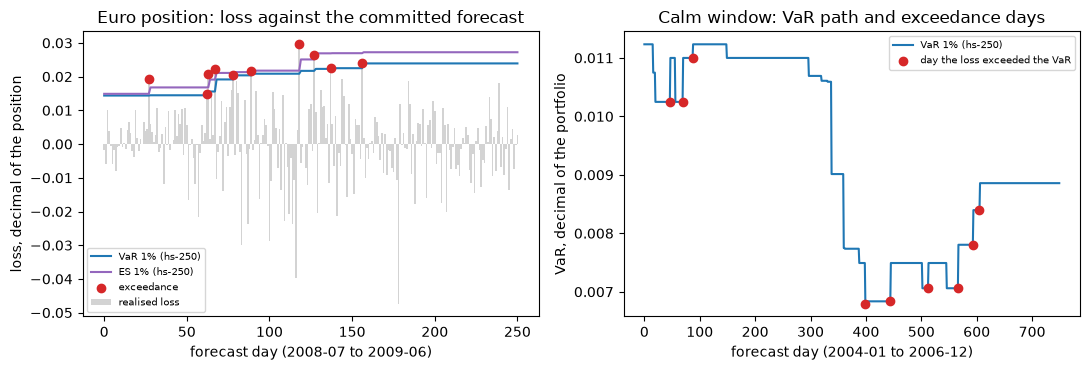

In [10]:
# Draw the euro position against its hs-250 forecast and the calm window's VaR path with its exceedance days
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8))

days = np.arange(loss.size)
var_fx, es_fx = np.array(level_1pct["var"]), np.array(level_1pct["es"])
hit = loss > var_fx
left.bar(days, loss, color="lightgrey", width=1.0, label="realised loss")
left.plot(days, var_fx, color="tab:blue", label="VaR 1% (hs-250)")
left.plot(days, es_fx, color="tab:purple", label="ES 1% (hs-250)")
left.scatter(days[hit], loss[hit], color="tab:red", zorder=3, label="exceedance")
left.set_xlabel("forecast day (2008-07 to 2009-06)")
left.set_ylabel("loss, decimal of the position")
left.set_title("Euro position: loss against the committed forecast")
left.legend(fontsize=7)

calm_level = calm_hs["by_level"][0]
var_calm = np.array(calm_level["var"])
right.plot(var_calm, color="tab:blue", label="VaR 1% (hs-250)")
right.scatter(calm_level["exceedance_days"], var_calm[calm_level["exceedance_days"]], color="tab:red", zorder=3, label="day the loss exceeded the VaR")
right.set_xlabel("forecast day (2004-01 to 2006-12)")
right.set_ylabel("VaR, decimal of the portfolio")
right.set_title("Calm window: VaR path and exceedance days")
right.legend(fontsize=7)
fig.tight_layout()
plt.show()

## Results

- **Convention.** The committed VaR is a positive loss number (0.014384 for the first days of the euro window) and the engine holds it as a negative return (-0.014384); the round trip through `from_loss_numbers` and `to_loss_numbers` is exact. A report that does not say which convention it uses is ambiguous by a sign.
- **The tail rests on a few days.** On the 251 returns the 1 percent VaR is 2.39 percent of the position and the ES 2.72 percent, and the tail weights are 1, 1 and 0.51: three days. Removing the single worst day moves the VaR by -5.9 percent and the ES by -9.3 percent at 1 percent, and by -2.3 and -5.8 percent at 2.5 percent. An ES estimated this way is more sensitive than the VaR, and a short window makes it more so.
- **A first back-test.** The 100-day historical simulation forecast the last 151 days with 1 exceedance at 1 percent (1.51 expected) and 4 at 2.5 percent (3.78 expected); Kupiec does not reject (asymptotic p 0.657 and 0.908). With one exceedance the exact binomial p-value (1.000) and the asymptotic one (0.657) are far apart: that is the small-count case the engine flags.
- **The committed `hs-250` on the crisis year.** It exceeds its 1 percent VaR 10 times against 2.51 expected (Kupiec p 0.00033, red) and its 2.5 percent VaR 13 times against 6.28 (p 0.017, red). Six of the ten exceedances at 1 percent fall before day 100 of the window, in the first months of the crisis, which the 100-day forecast of step 3 does not score; the two counts are on different days and are not comparable one to one.
- **The calm window.** `hs-250` has 9 exceedances at 1 percent in 750 days (7.50 expected, p 0.594, green) and 22 at 2.5 percent (18.75 expected, p 0.459). The flags rebuilt from the stored exceedance days alone give exactly the committed p-values, so a derived-only window can be back-tested for the count tests. The artifacts were baked with engine 0.7.0 and the notebook runs 0.8.1; the recomputed p-values equal the committed ones to six decimals.

What this notebook does not show: the dependence between exceedances (notebook 03), the ES forecast (notebook 04), the other estimators (notebook 02) or how to rank them (notebook 05).

## Summary

- The engine stores VaR and ES in the return convention (negative numbers) and the committed documents hold positive loss numbers; `to_loss_numbers` and `from_loss_numbers` are the only place the sign changes.
- A sample VaR is an order statistic and the ES a tail average with a fractional weight on the last observation; at 1 percent on about 250 days they rest on two or three days, so one observation moves them visibly.
- A forecast is made from information dated before the day it is about. Counting how often the realised loss exceeded it, against the $\alpha T$ expected, is the first back-test, and the Kupiec test says whether the count is compatible with the nominal level; with a small expected count read the exact p-value beside the asymptotic one.
- The exceedance tests need flags, not returns: a window whose returns are withheld by licence can still be back-tested from the stored exceedance days.

**What to try next.** Change `W` in step 3 to 60 and to 150 and watch the exceedance count and the Kupiec p-value; then continue with notebook 02, which goes through the whole ladder of estimators.

## References

- Kupiec, P. H. (1995), Techniques for verifying the accuracy of risk measurement models, Journal of Derivatives 3(2). https://doi.org/10.3905/jod.1995.407942
- Patton, A. J., Ziegel, J. F. and Chen, R. (2019), Dynamic semiparametric models for expected shortfall (and value-at-risk), Journal of Econometrics 211(2); the return convention, equations 1 and 2. https://arxiv.org/abs/1707.05108
- Basel Committee on Banking Supervision (1996), Supervisory framework for the use of backtesting in conjunction with the internal models approach to market risk capital requirements. https://www.bis.org/publ/bcbs22.htm
- Pritsker, M. (2001), The hidden dangers of historical simulation, Federal Reserve Board FEDS 2001-27. https://www.federalreserve.gov/Pubs/feds/2001/200127/200127pap.pdf
- Federal Reserve H.10 foreign exchange rates and the Kenneth French data library are the sources of the two windows; only derived values are committed (see the case page).